# Benchmark de la parte 3: búsqueda de texto
## TF-IDF + coseno vs. BM25 (índice SPIMI propio) vs. PostgreSQL GIN

**Pregunta:** ¿qué técnica conviene para buscar documentos por palabras clave, según el tamaño
de la colección y la longitud de la consulta?

Este notebook genera un corpus reproducible con juicios de relevancia, construye el índice
invertido del motor (`engine.fulltext.spimi`) y un índice GIN de PostgreSQL sobre los mismos
documentos. Ejecuta las mismas consultas con las tres técnicas y mide tiempo de construcción,
tiempo de consulta, Precision@10, Recall@10, memoria y disco. Las conclusiones se calculan con
los datos de esta corrida.

| Sección | Contenido |
| :-- | :-- |
| 1. Preparación | Entorno, corpus reproducible, juicios de relevancia y pruebas del motor |
| 2. Diseño experimental | Técnicas, consultas, métricas, unidades y caché |
| 3. Ejecución | Construcción y consultas en 1 000, 10 000 y 100 000 documentos |
| 4. Resultados | Tablas y gráficas de tiempo, relevancia y espacio |
| 5. Conclusiones | Análisis calculado y tabla de ventajas y desventajas |

**Reproducción:** ejecutar de arriba abajo desde la raíz o desde `benchmarks/`. Requiere
PostgreSQL (`initdb`, `pg_ctl`, extensión `pg_buffercache`) y las dependencias de
[README](README.md). El notebook crea un clúster PostgreSQL privado y temporal en `/tmp`,
con socket Unix propio y TCP deshabilitado, y lo elimina al terminar. No se conecta a
servidores existentes.

In [1]:
import csv
import hashlib
import json
import math
import os
import platform
import statistics
import subprocess
import sys
import tempfile
import tracemalloc
from collections import Counter, defaultdict
from datetime import datetime, timezone
from io import StringIO
from pathlib import Path
from time import perf_counter_ns

os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "bd2-mpl"))
import matplotlib.pyplot as plt
import psycopg2

ROOT = Path.cwd().resolve()
if ROOT.name == "benchmarks":
    ROOT = ROOT.parent
assert (ROOT / "backend" / "engine").is_dir(), "Ejecutar desde la raíz o benchmarks/"
sys.path.insert(0, str(ROOT / "backend"))
sys.path.insert(0, str(ROOT))

from data import generate_text
from engine.fulltext import spimi
from engine.fulltext.inverted_index import IndiceInvertido
from engine.fulltext.preprocess import bolsa
from engine.fulltext.ranking import B, BM25, K1, TF_IDF, buscar

# Parámetros. Para una comprobación corta: SIZES = (1_000,) y restaurar antes de publicar.
SIZES = (1_000, 10_000, 100_000)
SEED = 2026
TOP_K = 10
VERIFY_EVERY = 5          # una de cada 5 consultas se verifica contra fuerza bruta y barrido PostgreSQL
PG_PORT = 55440
DATA = ROOT / "data" / "generated"
OUT = ROOT / "benchmarks" / "text_results"
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)

METHODS = ("tfidf", "bm25", "gin")
LABELS = {"tfidf": "TF-IDF + coseno", "bm25": "BM25", "gin": "PostgreSQL GIN"}
COLORS = {"tfidf": "#0284c7", "bm25": "#16a34a", "gin": "#ea580c"}
LENGTHS = tuple(generate_text.QUERY_LENGTHS)
LENGTH_LABELS = {"1": "1 palabra", "3": "3 palabras", "5+": "5–7 palabras"}

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})

def table(headers, rows):
    """Tabla en texto plano con columnas alineadas."""
    rows = [[str(x) for x in row] for row in rows]
    widths = [max([len(str(h))] + [len(row[i]) for row in rows]) for i, h in enumerate(headers)]
    for row in [[str(h) for h in headers]] + rows:
        print("  ".join(x.ljust(w) for x, w in zip(row, widths)).rstrip())
    print()

def elapsed(action):
    started = perf_counter_ns()
    result = action()
    return result, (perf_counter_ns() - started) / 1_000_000

def p95(values):
    ordered = sorted(values)
    return ordered[math.ceil(len(ordered) * .95) - 1]

def write_csv(path, rows):
    with path.open("w", newline="", encoding="utf-8") as stream:
        writer = csv.DictWriter(stream, fieldnames=rows[0].keys())
        writer.writeheader()
        writer.writerows(rows)

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

engine_files = sorted((ROOT / "backend" / "engine" / "fulltext").glob("*.py")) + [ROOT / "data" / "generate_text.py"]
environment = dict(started_at=datetime.now(timezone.utc).isoformat(), python=sys.version, executable=sys.executable,
                   platform=platform.platform(), cpu_count=os.cpu_count(), seed=SEED, sizes=SIZES, top_k=TOP_K,
                   queries_per_length=generate_text.QUERIES_PER_LENGTH, verify_every=VERIFY_EVERY,
                   bm25=dict(k1=K1, b=B), spimi_block_postings=spimi.LIMITE_POSTINGS, spimi_fan_in=spimi.FAN_IN,
                   source_commit=subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=ROOT, text=True).strip(),
                   engine_sha256={str(p.relative_to(ROOT)): sha256(p) for p in engine_files},
                   p95_method="nearest_rank", cache="Caché caliente del SO y de PostgreSQL; una consulta de calentamiento por técnica")
table(["Configuración", "Valor"], [("Python", platform.python_version()), ("Tamaños", " · ".join(f"{n:,}" for n in SIZES)),
      ("Consultas por longitud", generate_text.QUERIES_PER_LENGTH), ("k", TOP_K), ("Semilla", SEED),
      ("BM25", f"k1 = {K1}, b = {B}"), ("Bloque SPIMI", f"{spimi.LIMITE_POSTINGS:,} postings, fan-in {spimi.FAN_IN}")])

Configuración           Valor
Python                  3.12.13
Tamaños                 1,000 · 10,000 · 100,000
Consultas por longitud  50
k                       10
Semilla                 2026
BM25                    k1 = 1.2, b = 0.75
Bloque SPIMI            200,000 postings, fan-in 64



## 1. Corpus, juicios de relevancia y pruebas

La especificación ([§2.3.3](../documents/proyectobd2.md)) pide colecciones de 1 000, 10 000 y
100 000 documentos y medir Precision@10 y Recall@10, así que hacen falta juicios de relevancia.
[`data/generate_text.py`](../data/generate_text.py) genera un corpus sintético donde la
relevancia se conoce por construcción:

- Cada documento pertenece a un **tema**. Hay un tema por cada 15 documentos en promedio, así
  que el número de relevantes por consulta no crece con la colección.
- Los temas se agrupan en **familias** de 10 que comparten 40 términos. Cada tema tiene además
  6 términos propios.
- Cada documento tiene de 40 a 160 tokens. Aproximadamente el 25 % son stopwords reales del
  español, el 12 % términos de su tema, el 15 % de su familia y el 4 % términos de otro tema
  elegido al azar (ruido que confunde). El resto viene de un vocabulario de fondo de
  5 000 palabras con distribución Zipf.
- Cada consulta se genera para un tema con al menos 5 documentos y no repite términos. El
  primero es del tema (60 %) o de su familia (40 %). Desde el segundo, el 25 % son palabras
  generales del vocabulario de fondo, cuyas listas de postings crecen con la colección, como
  pasa con palabras reales del tipo "datos" o "sistema". Hay 50 consultas de 1 palabra, 50 de 3
  y 50 de 5 a 7.
- **Relevantes:** los documentos del mismo tema que la consulta, tengan o no los términos.
  Por eso Recall@10 puede ser menor que 1 aunque la técnica sea correcta, y una consulta de
  una palabra de la familia es ambigua a propósito.

Las palabras son pseudopalabras con raíces distintas tras el stemming del motor, para que la
lematización no mezcle temas por accidente. Los CSV se generan solo si faltan; se validan y se
guardan sus SHA-256. Los tests del motor comprueban SPIMI y el ranking contra fuerza bruta, y la
integración SQL (`MATCH ... USING`, `SCORE()`). Su duración es diagnóstico, no una medición.

In [2]:
corpora = {}
fingerprints = {}
for n in SIZES:
    paths = (DATA / f"text_docs_{n}.csv", DATA / f"text_queries_{n}.csv")
    if not all(p.exists() for p in paths):
        generate_text.generate(n, SEED, DATA)
    with paths[0].open(newline="", encoding="utf-8") as f:
        reader = csv.reader(f); next(reader)
        docs = [(int(i), int(t), text) for i, t, text in reader]
    with paths[1].open(newline="", encoding="utf-8") as f:
        reader = csv.reader(f); next(reader)
        queries = [(int(i), length, int(t), text) for i, length, t, text in reader]
    relevant = defaultdict(set)
    for doc_id, topic, _ in docs:
        relevant[topic].add(doc_id)
    assert [d[0] for d in docs] == list(range(n)), f"IDs no consecutivos en {paths[0].name}"
    assert Counter(q[1] for q in queries) == {L: generate_text.QUERIES_PER_LENGTH for L in LENGTHS}
    for _, length, topic, text in queries:
        words = text.split()
        low, high = generate_text.QUERY_LENGTHS[length]
        assert low <= len(words) <= high and len(set(words)) == len(words) and len(relevant[topic]) >= 5
    for p in paths:
        fingerprints[p.name] = sha256(p)
    corpora[n] = (docs, queries, relevant)
environment["input_sha256"] = fingerprints
table(["Documentos", "Temas", "Tokens por documento (media)", "Relevantes por consulta (media)", "Consultas", "Validación"],
      [(f"{n:,}", f"{len(rel):,}", f"{statistics.mean(len(t.split()) for _, _, t in docs):.1f}",
        f"{statistics.mean(len(rel[q[2]]) for q in queries):.1f}", len(queries), "OK")
       for n, (docs, queries, rel) in corpora.items()])

tests = []
for module in ("engine.fulltext.test_fulltext", "engine.parser.test_fulltext_sql", "engine.parser.test_text_sql"):
    _, ms = elapsed(lambda: subprocess.run([sys.executable, "-B", "-m", module], cwd=ROOT / "backend",
                                           check=True, capture_output=True, text=True))
    tests.append((module, "OK", f"{ms / 1000:.1f}"))
table(["Prueba", "Resultado", "Duración (s)"], tests)

Documentos  Temas  Tokens por documento (media)  Relevantes por consulta (media)  Consultas  Validación
1,000       67     101.5                         15.0                             150        OK
10,000      667    100.2                         15.4                             150        OK
100,000     6,667  100.0                         14.8                             150        OK



Prueba                           Resultado  Duración (s)
engine.fulltext.test_fulltext    OK         0.3
engine.parser.test_fulltext_sql  OK         1.2
engine.parser.test_text_sql      OK         0.9



## 2. Diseño experimental

| Técnica | Índice | Consulta y ranking |
| :-- | :-- | :-- |
| TF-IDF + coseno | Índice invertido SPIMI del motor: bloques en disco de 200 000 postings, mezcla k-way, archivos `.post`/`.lex`/`.docs` | `buscar(..., TF_IDF, k=10)`: pesos `log10(1+tf)·idf`, normas precalculadas |
| BM25 | El mismo índice SPIMI (se construye una sola vez para ambas) | `buscar(..., BM25, k=10)`, k1 = 1.2, b = 0.75 |
| PostgreSQL GIN | Columna `tsvector` generada con `to_tsvector('spanish', ...)` e índice `GIN` | `tsv @@ to_tsquery('spanish', 't1 \| t2 \| ...')` ordenado por `ts_rank` y `id`, `LIMIT 10` |

- **Mismas consultas:** las tres técnicas usan una disyunción de los términos (OR), igual que
  `MATCH` del motor. El preprocesamiento es equivalente: stopwords y stemming Snowball en
  español en ambos lados.
- **Construcción:** SPIMI incluye tokenización, stemming, bloques y mezcla. En PostgreSQL se
  separa la **vectorización** (`ALTER TABLE ... ADD COLUMN tsv ... GENERATED`) del
  `CREATE INDEX ... USING gin`. La carga con `COPY` se registra aparte y no se suma.
- **Consulta:** 150 consultas por tamaño (50 por longitud), con una de calentamiento por
  técnica. El orden de las técnicas rota entre consultas. El tiempo incluye producir los 10 IDs.
  En PostgreSQL incluye planificación, ejecución y viaje por socket local; el motor corre en el
  mismo proceso. Se desactivan el barrido secuencial y el paralelismo para medir el GIN.
- **Relevancia:** Precision@10 = aciertos / 10; Recall@10 = aciertos / relevantes del tema.
  Se promedian por longitud de consulta.
- **Verificación fuera del cronómetro:** en una de cada 5 consultas, el top-10 del motor se
  compara con TF-IDF y BM25 calculados por fuerza bruta (mismos puntajes y mismos IDs salvo
  empates en el décimo lugar). El GIN se compara con la misma consulta ejecutada con barrido
  secuencial, y `EXPLAIN ANALYZE` debe mostrar `docs_gin`.
- **Memoria:** del motor se miden con `tracemalloc` el pico de construcción (en una segunda
  construcción, sin cronómetro) y lo que queda en RAM al abrir el índice (léxico, longitudes y
  normas). Los postings se leen del archivo en cada consulta. De PostgreSQL se miden, al terminar
  las consultas y antes de la verificación, las páginas del GIN y de la tabla (con su TOAST) que
  están en `shared_buffers` (`pg_buffercache`). No es la memoria total de ninguno de los dos
  procesos.
- **Disco:** archivos del índice SPIMI frente a `pg_relation_size` del GIN. GIN no guarda las
  frecuencias; `ts_rank` las lee del `tsvector` de la tabla, así que también se informa el
  tamaño de esa columna.

In [3]:
def pg_tsquery(text):
    return " | ".join(text.split())

PG_SEARCH = ("SELECT id FROM docs, to_tsquery('spanish', %s) q WHERE tsv @@ q "
             "ORDER BY ts_rank(tsv, q) DESC, id LIMIT %s")

def gin_search(cursor, text):
    cursor.execute(PG_SEARCH, (pg_tsquery(text), TOP_K))
    return [row[0] for row in cursor.fetchall()]

def engine_search(index, text, method):
    return [(score, index.rid(doc)[0]) for score, doc in buscar(index, text, method, TOP_K)]

def brute_force_model(docs):
    bags = [bolsa(text) for _, _, text in docs]
    df = Counter(term for freqs, _ in bags for term in freqs)
    total = len(bags)
    norms = [math.sqrt(sum((math.log10(1 + tf) * math.log10(total / df[t])) ** 2 for t, tf in freqs.items()))
             for freqs, _ in bags]
    return bags, df, norms, sum(length for _, length in bags) / total

def brute_force(model, text, method):
    bags, df, norms, average = model
    total = len(bags)
    query, _ = bolsa(text)
    query = {t: tf for t, tf in query.items() if df[t]}
    scores = []
    if method == TF_IDF:
        weights = {t: math.log10(1 + tf) * math.log10(total / df[t]) for t, tf in query.items()}
        qnorm = math.sqrt(sum(w * w for w in weights.values()))
        for doc, (freqs, _) in enumerate(bags):
            dot = sum(w * math.log10(1 + freqs[t]) * math.log10(total / df[t]) for t, w in weights.items() if t in freqs)
            if dot > 0:
                scores.append((dot / (qnorm * norms[doc]), doc))
    else:
        for doc, (freqs, length) in enumerate(bags):
            value = 0.0
            for t, qtf in query.items():
                if t in freqs:
                    idf = math.log((total - df[t] + .5) / (df[t] + .5) + 1)
                    value += qtf * idf * freqs[t] * (K1 + 1) / (freqs[t] + K1 * (1 - B + B * length / average))
            if value > 0:
                scores.append((value, doc))
    scores.sort(key=lambda pair: (-pair[0], pair[1]))
    return scores[:TOP_K]

def assert_same_ranking(found, expected, context):
    assert len(found) == len(expected), context
    for (a, _), (b, _) in zip(found, expected):
        assert abs(a - b) <= 1e-9 * max(1.0, abs(b)), (context, a, b)
    if expected:
        tenth = expected[-1][0]
        # Los empates con el último puntaje pueden ordenarse distinto; lo demás debe coincidir.
        strict = lambda rows: {i for s, i in rows if s > tenth + 1e-9 * max(1.0, abs(tenth))}
        assert strict(found) == strict(expected), context

## 3. Ejecución

Para cada tamaño: se construyen el índice SPIMI y el GIN, se mide la memoria y el disco, se
ejecutan las 150 consultas con las tres técnicas y se verifican las muestras. Un fallo detiene
la corrida, conserva el error en el notebook y detiene el clúster.

In [4]:
construction, samples, plans, verified = [], [], [], Counter()

def run_size(cursor, work, n):
    docs, queries, relevant = corpora[n]
    path = str(Path(work) / f"ft_{n}")
    print(f"N={n:,}: construcción SPIMI", flush=True)
    meta, spimi_ms = elapsed(lambda: spimi.construir((((doc_id, 0), text) for doc_id, _, text in docs), path))
    tracemalloc.start()
    spimi.construir((((doc_id, 0), text) for doc_id, _, text in docs), path + "_peak")
    _, build_peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    spimi.destruir(path + "_peak")
    tracemalloc.start()
    index = IndiceInvertido(path)
    retained, _ = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    assert index.documentos == n and meta["documentos"] == n

    print(f"N={n:,}: construcción GIN", flush=True)
    cursor.execute("DROP TABLE IF EXISTS docs; CREATE TABLE docs (id integer PRIMARY KEY, body text NOT NULL)")
    buffer = StringIO()
    csv.writer(buffer, lineterminator="\n").writerows((doc_id, text) for doc_id, _, text in docs)
    buffer.seek(0)
    _, load_ms = elapsed(lambda: cursor.copy_expert("COPY docs(id, body) FROM STDIN WITH CSV", buffer))
    _, vector_ms = elapsed(lambda: cursor.execute(
        "ALTER TABLE docs ADD COLUMN tsv tsvector GENERATED ALWAYS AS (to_tsvector('spanish', body)) STORED"))
    _, gin_ms = elapsed(lambda: cursor.execute("CREATE INDEX docs_gin ON docs USING gin(tsv)"))
    cursor.execute("ANALYZE docs")
    cursor.execute("SELECT pg_relation_size('docs_gin'), pg_table_size('docs'), sum(pg_column_size(tsv)) FROM docs")
    gin_disk, table_disk, tsvector_bytes = cursor.fetchone()

    print(f"N={n:,}: {len(queries)} consultas × {len(METHODS)} técnicas", flush=True)
    operations = {"tfidf": lambda text: engine_search(index, text, TF_IDF),
                  "bm25": lambda text: engine_search(index, text, BM25),
                  "gin": lambda text: gin_search(cursor, text)}
    for action in operations.values():
        action(queries[0][3])
    results = {}
    for position, (query_id, length, topic, text) in enumerate(queries):
        order = list(METHODS)
        order = order[position % 3:] + order[:position % 3]
        for method in order:
            found, ms = elapsed(lambda: operations[method](text))
            ids = [doc for _, doc in found] if method != "gin" else found
            hits = len(set(ids) & relevant[topic])
            results[method, query_id] = found
            samples.append(dict(n=n, metodo=method, consulta=query_id, longitud=length, tema=topic,
                                relevantes=len(relevant[topic]), devueltos=len(ids), aciertos=hits,
                                precision_10=hits / TOP_K, recall_10=hits / len(relevant[topic]), tiempo_ms=ms))

    # Antes de la verificación: el barrido secuencial desalojaría páginas del GIN.
    cache_sql = '''SELECT count(*) * current_setting('block_size')::bigint FROM pg_buffercache
                   WHERE relfilenode = pg_relation_filenode(%s::regclass) AND relforknumber = 0
                   AND reldatabase = (SELECT oid FROM pg_database WHERE datname = current_database())'''
    cursor.execute(cache_sql, ("docs_gin",))
    gin_cache = cursor.fetchone()[0]
    cursor.execute("SELECT reltoastrelid::regclass::text FROM pg_class WHERE oid = 'docs'::regclass")
    toast = cursor.fetchone()[0]
    table_cache = 0
    for relation in ("docs", toast):
        cursor.execute(cache_sql, (relation,))
        table_cache += cursor.fetchone()[0]

    print(f"N={n:,}: verificación", flush=True)
    model = brute_force_model(docs)
    checked = queries[::VERIFY_EVERY]
    for query_id, _, _, text in checked:
        for method, name in ((TF_IDF, "tfidf"), (BM25, "bm25")):
            expected = [(s, docs[d][0]) for s, d in brute_force(model, text, method)]
            assert_same_ranking(results[name, query_id], expected, (n, name, query_id))
    cursor.execute("SET enable_seqscan = on; SET enable_bitmapscan = off; SET enable_indexscan = off")
    for query_id, _, _, text in checked:
        assert gin_search(cursor, text) == results["gin", query_id], (n, "gin", query_id)
    cursor.execute("SET enable_seqscan = off; SET enable_bitmapscan = on; SET enable_indexscan = on")
    verified[n] = len(checked)
    for length in LENGTHS:
        text = next(q[3] for q in queries if q[1] == length)
        cursor.execute("EXPLAIN (ANALYZE, BUFFERS, FORMAT JSON) " + PG_SEARCH, (pg_tsquery(text), TOP_K))
        plan = cursor.fetchone()[0][0]
        assert "docs_gin" in json.dumps(plan), "GIN no utilizado"
        plans.append(dict(n=n, longitud=length, consulta=text, plan=plan))

    spimi_disk = index.bytes_en_disco()
    for method in METHODS:
        own = method != "gin"
        construction.append(dict(
            n=n, metodo=method, construccion_ms=spimi_ms if own else gin_ms, vectorizacion_ms="" if own else vector_ms,
            carga_pg_ms="" if own else load_ms, indice_disco_bytes=spimi_disk if own else gin_disk,
            tsvector_bytes="" if own else tsvector_bytes, tabla_pg_bytes="" if own else table_disk,
            ram_abierto_bytes=retained if own else "", ram_pico_construccion_bytes=build_peak if own else "",
            gin_cache_bytes="" if own else gin_cache, tabla_cache_bytes="" if own else table_cache, terminos=meta["terminos"], postings=meta["postings"],
            bloques_spimi=meta["bloques"] if own else ""))
    spimi.destruir(path)

with tempfile.TemporaryDirectory(prefix="bd2-text-pg-") as work:
    cluster, socket = Path(work) / "data", Path(work) / "socket"
    socket.mkdir()
    log = Path(work) / "postgres.log"
    subprocess.run(["initdb", "-D", str(cluster), "-A", "trust", "--no-locale", "-E", "UTF8"], check=True, stdout=subprocess.DEVNULL)
    try:
        subprocess.run(["pg_ctl", "-D", str(cluster), "-l", str(log), "-o",
                        f"-h '' -k {socket} -p {PG_PORT} -c shared_buffers=64MB -c max_connections=10", "-w", "start"],
                       check=True, stdout=subprocess.DEVNULL)
    except subprocess.CalledProcessError:
        print(log.read_text(), file=sys.stderr)
        raise
    try:
        with psycopg2.connect(host=str(socket), port=PG_PORT, dbname="postgres") as connection:
            connection.autocommit = True
            with connection.cursor() as cursor:
                cursor.execute("CREATE EXTENSION pg_buffercache")
                cursor.execute("SET enable_seqscan = off; SET max_parallel_workers_per_gather = 0")
                cursor.execute("SELECT version(), current_setting('shared_buffers'), current_setting('maintenance_work_mem')")
                environment["postgresql"], environment["pg_shared_buffers"], environment["pg_maintenance_work_mem"] = cursor.fetchone()
                for n in SIZES:
                    run_size(cursor, work, n)
    finally:
        subprocess.run(["pg_ctl", "-D", str(cluster), "-m", "fast", "-w", "stop"], check=True, stdout=subprocess.DEVNULL)

environment["finished_at"] = datetime.now(timezone.utc).isoformat()
environment["verified_queries"] = dict(verified)
table(["Documentos", "Consultas medidas", "Consultas verificadas", "Planes GIN"],
      [(f"{n:,}", sum(1 for s in samples if s["n"] == n) // len(METHODS), verified[n],
        sum(1 for p in plans if p["n"] == n)) for n in SIZES])

N=1,000: construcción SPIMI


N=1,000: construcción GIN


N=1,000: 150 consultas × 3 técnicas


N=1,000: verificación


N=10,000: construcción SPIMI


N=10,000: construcción GIN


... (3 outputs left out)

N=100,000: construcción GIN


N=100,000: 150 consultas × 3 técnicas


N=100,000: verificación


Documentos  Consultas medidas  Consultas verificadas  Planes GIN
1,000       150                30                     3
10,000      150                30                     3
100,000     150                30                     3



## 4. Resultados

Los tiempos de consulta están en milisegundos por consulta; la construcción, en segundos; el
espacio, en MiB. El P95 usa rango más cercano: la posición `ceil(0.95 × n)` en los tiempos
ordenados.

In [5]:
summary = []
for n in SIZES:
    for method in METHODS:
        for length in LENGTHS + ("todas",):
            rows = [s for s in samples if s["n"] == n and s["metodo"] == method and (length == "todas" or s["longitud"] == length)]
            times = [r["tiempo_ms"] for r in rows]
            summary.append(dict(n=n, metodo=method, longitud=length, consultas=len(rows),
                                promedio_ms=statistics.mean(times), mediana_ms=statistics.median(times), p95_ms=p95(times),
                                precision_10=statistics.mean(r["precision_10"] for r in rows),
                                recall_10=statistics.mean(r["recall_10"] for r in rows),
                                devueltos=statistics.mean(r["devueltos"] for r in rows), verificadas=True))
write_csv(OUT / "consultas.csv", summary)
write_csv(OUT / "muestras.csv", samples)
write_csv(OUT / "construccion.csv", construction)
(OUT / "planes.json").write_text(json.dumps(plans, indent=2), encoding="utf-8")
(OUT / "entorno.json").write_text(json.dumps(environment, indent=2, default=str), encoding="utf-8")

def get(n, method, length, field):
    return next(r[field] for r in summary if r["n"] == n and r["metodo"] == method and r["longitud"] == length)

print("Tiempo de consulta y relevancia por longitud de consulta")
table(["Documentos", "Consulta", "Técnica", "Promedio (ms)", "P95 (ms)", "Precision@10", "Recall@10"],
      [(f"{r['n']:,}", LENGTH_LABELS.get(r["longitud"], "Todas"), LABELS[r["metodo"]], f"{r['promedio_ms']:.3f}",
        f"{r['p95_ms']:.3f}", f"{r['precision_10']:.3f}", f"{r['recall_10']:.3f}") for r in summary])

Tiempo de consulta y relevancia por longitud de consulta
Documentos  Consulta      Técnica          Promedio (ms)  P95 (ms)  Precision@10  Recall@10
1,000       1 palabra     TF-IDF + coseno  0.087          0.123     0.610         0.399
1,000       3 palabras    TF-IDF + coseno  0.202          0.514     0.848         0.604
1,000       5–7 palabras  TF-IDF + coseno  0.388          0.698     0.874         0.609
1,000       Todas         TF-IDF + coseno  0.226          0.638     0.777         0.537
1,000       1 palabra     BM25             0.072          0.118     0.608         0.399
1,000       3 palabras    BM25             0.202          0.679     0.820         0.589
1,000       5–7 palabras  BM25             0.406          0.830     0.830         0.575
1,000       Todas         BM25             0.227          0.685     0.753         0.521
1,000       1 palabra     PostgreSQL GIN   0.467          0.667     0.602         0.392
1,000       3 palabras    PostgreSQL GIN   0.817          1

In [6]:
MiB = 2 ** 20
print("Construcción, memoria y disco")
rows = []
for n in SIZES:
    own = next(c for c in construction if c["n"] == n and c["metodo"] == "tfidf")
    gin = next(c for c in construction if c["n"] == n and c["metodo"] == "gin")
    rows.append((f"{n:,}", "SPIMI (TF-IDF y BM25)", f"{own['construccion_ms'] / 1000:.2f}", "—",
                 f"{own['indice_disco_bytes'] / MiB:.2f}", "—", f"{own['ram_abierto_bytes'] / MiB:.2f}",
                 f"{own['ram_pico_construccion_bytes'] / MiB:.2f}", f"{own['bloques_spimi']}", f"{own['terminos']:,}"))
    rows.append((f"{n:,}", "PostgreSQL GIN", f"{gin['construccion_ms'] / 1000:.2f}", f"{gin['vectorizacion_ms'] / 1000:.2f}",
                 f"{gin['indice_disco_bytes'] / MiB:.2f}", f"{gin['tsvector_bytes'] / MiB:.2f}", "—",
                 f"GIN {gin['gin_cache_bytes'] / MiB:.2f} · tabla {gin['tabla_cache_bytes'] / MiB:.2f} (shared_buffers)", "—", "—"))
table(["Documentos", "Índice", "Índice (s)", "Vectorización PG (s)", "Disco índice (MiB)", "Columna tsvector (MiB)",
       "RAM abierto (MiB)", "RAM pico / caché (MiB)", "Bloques SPIMI", "Términos"], rows)

Construcción, memoria y disco
Documentos  Índice                 Índice (s)  Vectorización PG (s)  Disco índice (MiB)  Columna tsvector (MiB)  RAM abierto (MiB)  RAM pico / caché (MiB)                   Bloques SPIMI  Términos
1,000       SPIMI (TF-IDF y BM25)  0.25        —                     0.55                —                       0.73               4.10                                     1              4,904
1,000       PostgreSQL GIN         0.02        0.11                  0.52                0.86                    —                  GIN 0.52 · tabla 1.80 (shared_buffers)   —              —
10,000      SPIMI (TF-IDF y BM25)  1.38        —                     4.70                —                       3.06               14.56                                    3              11,682
10,000      PostgreSQL GIN         0.20        1.12                  3.16                8.48                    —                  GIN 3.16 · tabla 16.91 (shared_buffers)  —              —
100,

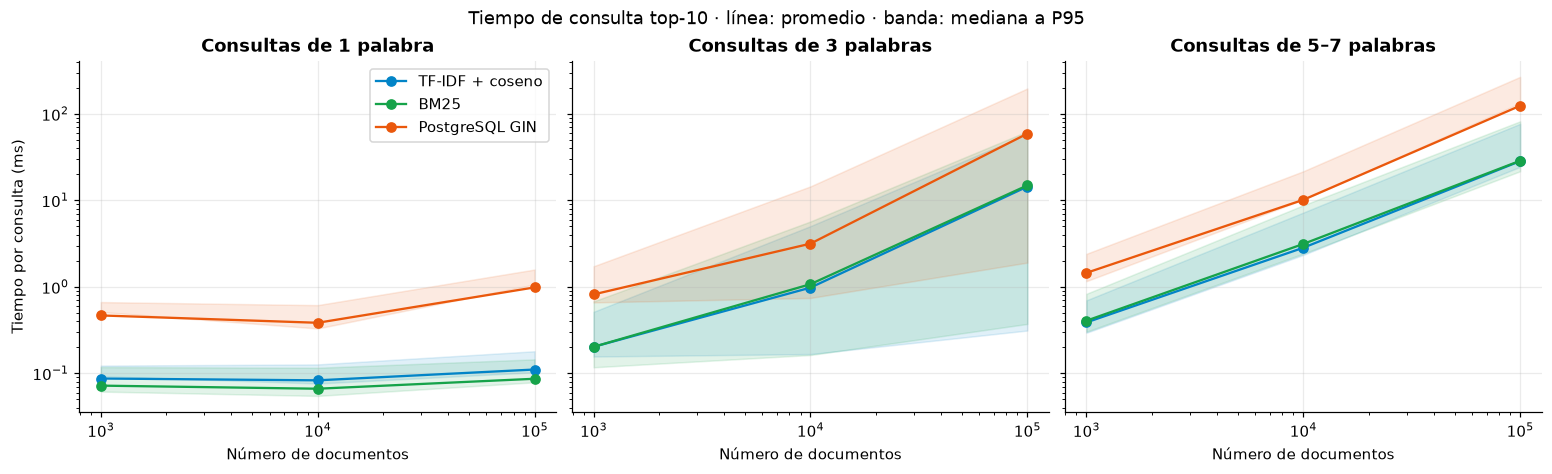

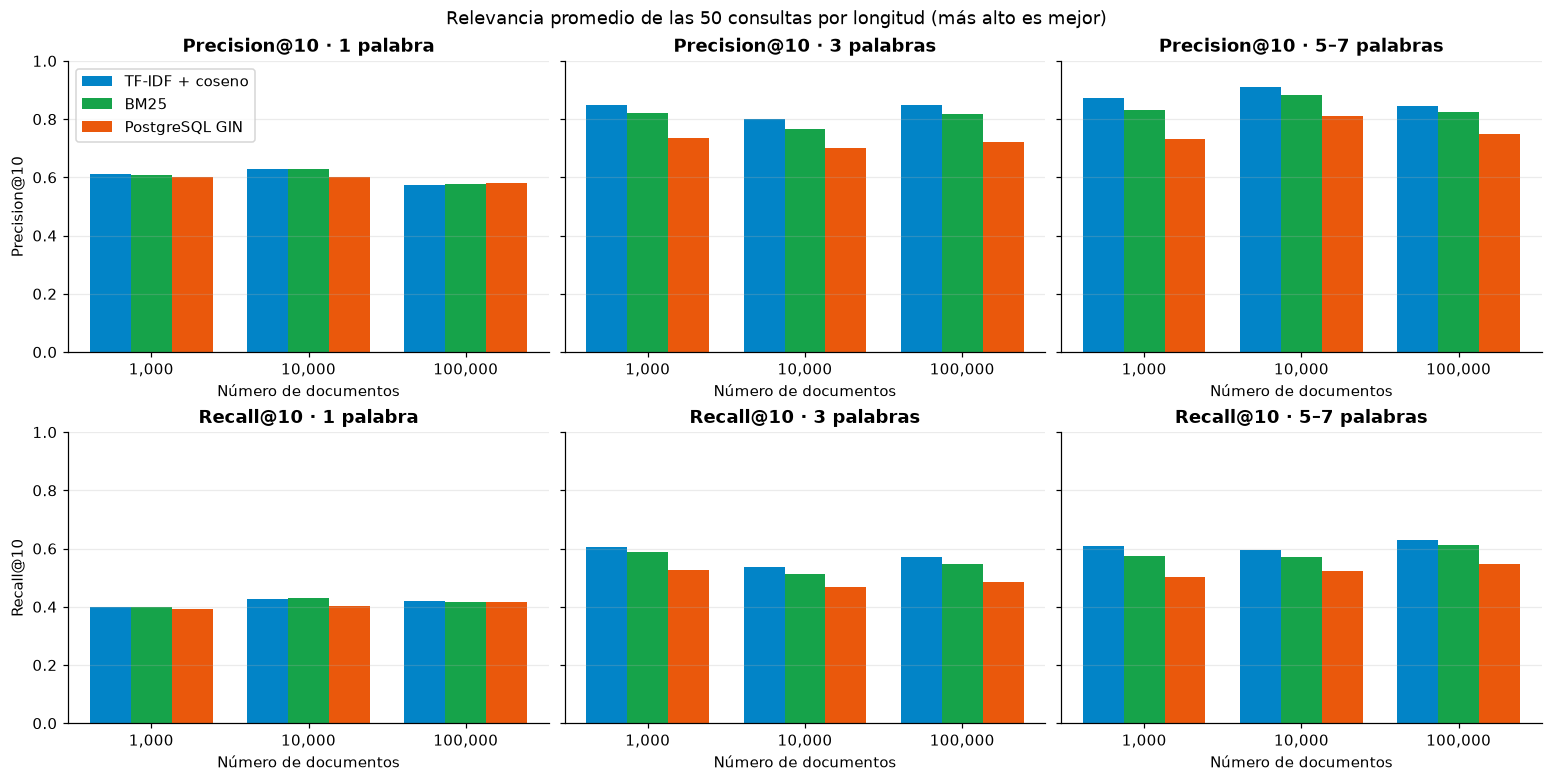

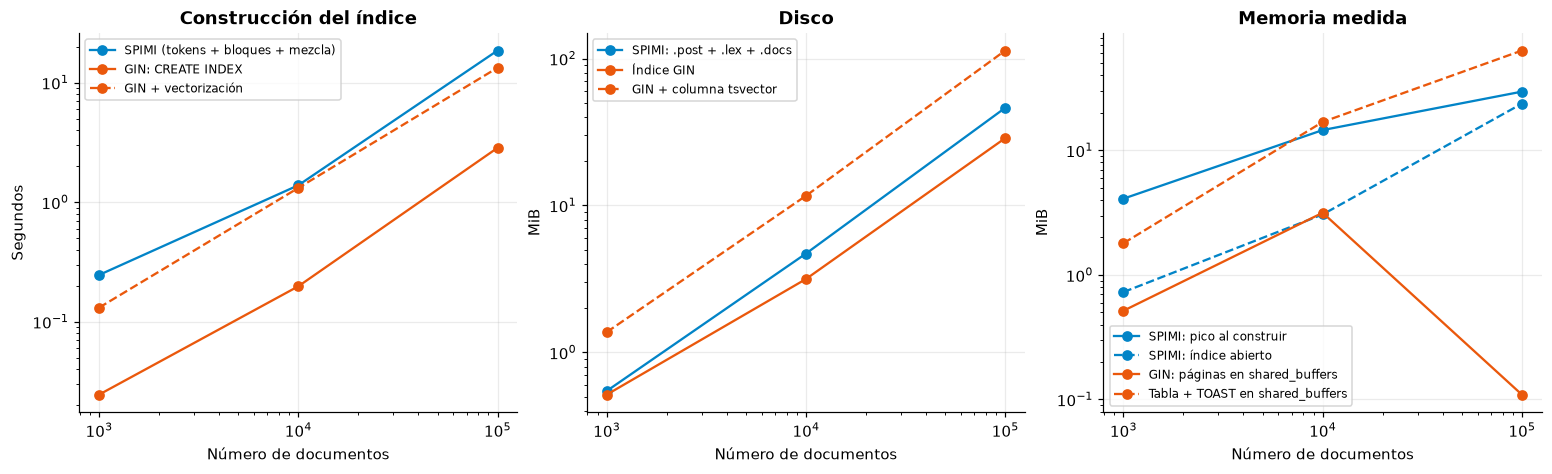

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True, sharey=True)
for ax, length in zip(axes, LENGTHS):
    for method in METHODS:
        ax.plot(SIZES, [get(n, method, length, "promedio_ms") for n in SIZES], "o-", color=COLORS[method], label=LABELS[method])
        ax.fill_between(SIZES, [get(n, method, length, "mediana_ms") for n in SIZES],
                        [get(n, method, length, "p95_ms") for n in SIZES], color=COLORS[method], alpha=.12)
    ax.set(xscale="log", yscale="log", xlabel="Número de documentos", title=f"Consultas de {LENGTH_LABELS[length]}")
    ax.grid(True, alpha=.25)
axes[0].set_ylabel("Tiempo por consulta (ms)")
axes[0].legend()
fig.suptitle("Tiempo de consulta top-10 · línea: promedio · banda: mediana a P95")
fig.savefig(OUT / "consultas.png", dpi=160)
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(14, 7), constrained_layout=True, sharey="row")
width = .26
for column, length in enumerate(LENGTHS):
    for row, (field, label) in enumerate((("precision_10", "Precision@10"), ("recall_10", "Recall@10"))):
        ax = axes[row, column]
        for offset, method in enumerate(METHODS):
            xs = [i + (offset - 1) * width for i in range(len(SIZES))]
            ax.bar(xs, [get(n, method, length, field) for n in SIZES], width, color=COLORS[method], label=LABELS[method])
        ax.set_xticks(range(len(SIZES)), [f"{n:,}" for n in SIZES])
        ax.set(ylim=(0, 1), xlabel="Número de documentos", ylabel=label if column == 0 else None,
               title=f"{label} · {LENGTH_LABELS[length]}")
        ax.grid(True, axis="y", alpha=.25)
axes[0, 0].legend(loc="upper left")
fig.suptitle("Relevancia promedio de las 50 consultas por longitud (más alto es mejor)")
fig.savefig(OUT / "relevancia.png", dpi=160)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)
own = [c for c in construction if c["metodo"] == "tfidf"]
gin = [c for c in construction if c["metodo"] == "gin"]
axes[0].plot(SIZES, [c["construccion_ms"] / 1000 for c in own], "o-", color=COLORS["tfidf"], label="SPIMI (tokens + bloques + mezcla)")
axes[0].plot(SIZES, [c["construccion_ms"] / 1000 for c in gin], "o-", color=COLORS["gin"], label="GIN: CREATE INDEX")
axes[0].plot(SIZES, [(c["construccion_ms"] + c["vectorizacion_ms"]) / 1000 for c in gin], "o--", color=COLORS["gin"], label="GIN + vectorización")
axes[0].set(xscale="log", yscale="log", xlabel="Número de documentos", ylabel="Segundos", title="Construcción del índice")
axes[1].plot(SIZES, [c["indice_disco_bytes"] / MiB for c in own], "o-", color=COLORS["tfidf"], label="SPIMI: .post + .lex + .docs")
axes[1].plot(SIZES, [c["indice_disco_bytes"] / MiB for c in gin], "o-", color=COLORS["gin"], label="Índice GIN")
axes[1].plot(SIZES, [(c["indice_disco_bytes"] + c["tsvector_bytes"]) / MiB for c in gin], "o--", color=COLORS["gin"], label="GIN + columna tsvector")
axes[1].set(xscale="log", yscale="log", xlabel="Número de documentos", ylabel="MiB", title="Disco")
axes[2].plot(SIZES, [c["ram_pico_construccion_bytes"] / MiB for c in own], "o-", color=COLORS["tfidf"], label="SPIMI: pico al construir")
axes[2].plot(SIZES, [c["ram_abierto_bytes"] / MiB for c in own], "o--", color=COLORS["tfidf"], label="SPIMI: índice abierto")
axes[2].plot(SIZES, [c["gin_cache_bytes"] / MiB for c in gin], "o-", color=COLORS["gin"], label="GIN: páginas en shared_buffers")
axes[2].plot(SIZES, [c["tabla_cache_bytes"] / MiB for c in gin], "o--", color=COLORS["gin"], label="Tabla + TOAST en shared_buffers")
axes[2].set(xscale="log", yscale="log", xlabel="Número de documentos", ylabel="MiB", title="Memoria medida")
for ax in axes:
    ax.grid(True, alpha=.25)
    ax.legend(fontsize=8)
fig.savefig(OUT / "construccion_espacio.png", dpi=160)
plt.show()

## 5. Conclusiones

El análisis está escrito con las cifras de la corrida guardada en este notebook (`text_results/`). Si se vuelve a ejecutar, hay que actualizarlo. Describe esta distribución sintética, esta máquina y la caché caliente; no permite generalizar a textos reales, a índices en frío ni a consultas concurrentes.

### Análisis

**Tiempo de consulta con 100 000 documentos**

| Consulta | TF-IDF + coseno | BM25 | PostgreSQL GIN |
| :-- | --: | --: | --: |
| 1 palabra | 0,11 ms | 0,09 ms | 0,99 ms |
| 3 palabras | 14,4 ms | 14,9 ms | 59,1 ms |
| 5–7 palabras | 28,4 ms | 28,7 ms | 124,1 ms |

- **Motor contra GIN.** El índice SPIMI responde unas 4 veces más rápido que GIN en las consultas de
  varias palabras, y unas 9 veces más rápido en las de una palabra. GIN encuentra los candidatos muy
  rápido, pero `ts_rank` tiene que leer el `tsvector` de cada candidato desde la tabla. Al terminar,
  `shared_buffers` (64 MB) tenía 63,3 MiB de la tabla y apenas 0,11 MiB del GIN: la tabla no cabe en
  la caché y esas lecturas desalojan al índice. El motor, en cambio, guarda `tf` en los postings y
  las normas en memoria, así que no vuelve a leer los documentos.
- **TF-IDF y BM25 cuestan lo mismo.** Recorren las mismas listas de postings del mismo índice y solo
  cambia la fórmula del puntaje. Las diferencias de 0,3 a 0,5 ms están dentro de la variación entre
  consultas: los P95 son de 2,7 a 4 veces el promedio.
- **Crecimiento.** De 1 000 a 100 000 documentos (100 veces más), el tiempo promedio de todas las
  consultas se multiplica por 63 (TF-IDF), 64 (BM25) y 67 (GIN). Es casi lineal porque el 25 % de los
  términos de las consultas largas son palabras generales, cuyas listas de postings crecen con la
  colección. Las consultas de una palabra apenas crecen (de 0,09 a 0,11 ms en TF-IDF), porque usan
  términos del tema o de la familia, cuyas listas no crecen.

**Relevancia con 100 000 documentos**

| Consulta | Precision@10 (TF-IDF / BM25 / GIN) | Recall@10 (TF-IDF / BM25 / GIN) |
| :-- | :-- | :-- |
| 1 palabra | 0,574 / 0,578 / 0,582 | 0,419 / 0,418 / 0,416 |
| 3 palabras | 0,848 / 0,818 / 0,720 | 0,572 / 0,549 / 0,484 |
| 5–7 palabras | 0,846 / 0,824 / 0,748 | 0,629 / 0,611 / 0,547 |

- **Con una palabra, las tres técnicas empatan.** Las diferencias son menores a 0,01 con 50 consultas,
  y no permiten elegir una. Con un solo término, las tres ordenan la misma lista de candidatos casi
  por la misma señal: la frecuencia del término en el documento.
- **Con varias palabras, GIN queda claramente por debajo** (0,08 a 0,13 menos de Precision@10). La
  causa es teórica: `ts_rank` no usa `idf`, así que una palabra general pesa lo mismo que una del
  tema. TF-IDF y BM25 bajan el peso de las palabras frecuentes.
- **TF-IDF queda 0,02–0,03 por encima de BM25**, al revés de lo que suele observarse en colecciones
  reales. La diferencia es pequeña para 50 consultas por longitud y no hay prueba estadística que la
  respalde. Además, el corpus sintético tiene longitudes de 40 a 160 tokens y términos del tema en
  proporción fija, así que la normalización por longitud de BM25 (b = 0,75), su principal ventaja,
  tiene poco que corregir.
- **Recall@10 no llega a 1 aunque la técnica sea correcta.** Cada tema tiene unos 15 documentos
  relevantes y solo se devuelven 10, así que el máximo posible ronda 0,67.

**Construcción y espacio con 100 000 documentos**

- **Construcción.** SPIMI tarda 18,6 s en 29 bloques (tokenización y stemming en Python). GIN tarda
  2,9 s más 10,5 s de vectorización (`to_tsvector` en C).
- **Disco.** SPIMI ocupa 46,2 MiB, porque guarda `tf` y normas. GIN ocupa 28,7 MiB, pero `ts_rank`
  además necesita la columna `tsvector`, que suma 84,6 MiB.
- **Memoria.** El índice SPIMI abierto retiene 23,7 MiB (léxico, longitudes y normas), y su
  construcción llegó a un pico de 29,6 MiB. Ese límite lo pone el tamaño del bloque, no el de la
  colección.

### Ventajas, desventajas y cuándo usar cada técnica

| Técnica | Ventajas | Desventajas | Cuándo usarla |
| :-- | :-- | :-- | :-- |
| TF-IDF + coseno (SPIMI) | Puntaje acotado en [0, 1] y fácil de explicar; las normas se precalculan al construir; SPIMI construye con memoria limitada por bloque | No satura la frecuencia de un término y favorece documentos cortos solo mediante la norma; reconstrucción completa ante cualquier cambio en la tabla | Colecciones estables donde se quiere un puntaje de similitud comparable entre consultas |
| BM25 (SPIMI) | Satura `tf` (k1) y normaliza por longitud (b); comparte el índice con TF-IDF, sin costo extra de construcción | Dos parámetros que dependen del corpus; el puntaje no está acotado y no se compara entre consultas | Ranking por relevancia en general, sobre todo con documentos de longitudes muy distintas |
| PostgreSQL GIN | Mantenimiento incremental (pending list), transacciones, concurrencia y persistencia; filtrado `@@` muy eficiente | No guarda frecuencias: `ts_rank` lee el `tsvector` de cada candidato; ese ranking no es TF-IDF ni BM25 (no usa `idf`); requiere el servidor | Aplicaciones en producción que filtran texto junto con otros datos y se actualizan seguido |

Los usos combinan las mediciones anteriores con propiedades conocidas de cada implementación;
no se afirma un umbral universal de tamaño. Las diferencias de relevancia vienen del modelo de
ranking, porque las tres técnicas evalúan la misma disyunción de términos con preprocesamiento
equivalente.

## Archivos de esta corrida

- [Resumen por técnica, tamaño y longitud](text_results/consultas.csv) y [cada consulta](text_results/muestras.csv)
  con tiempo, aciertos, Precision@10 y Recall@10.
- [Construcción, memoria y disco](text_results/construccion.csv), [planes GIN](text_results/planes.json)
  y [entorno, parámetros y hashes](text_results/entorno.json).
- Figuras: [consultas](text_results/consultas.png), [relevancia](text_results/relevancia.png) y
  [construcción y espacio](text_results/construccion_espacio.png).
- [Generador del corpus](../data/generate_text.py), [documentación de búsqueda de texto](../docs/12-texto.md)
  y [enunciado](../documents/proyectobd2.md).

Los CSV de entrada son regenerables y quedan en `data/generated/`.